## Assignment 15 — Core Algorithms, Metrics & Model Behavior

### Part 1 - Regression Algorithm

#### Task 1: Linear Regression

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Load Dataset
df = pd.read_csv("Superstore.csv", encoding="latin1")

df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

In [24]:
df.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,region,product_id,category,sub-category,product_name,sales,quantity,discount,profit,profitable
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,1
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,1
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,1
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,0
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,1


Sample Linear Regression Predictions: [232.16210057 126.68161285 152.42850805 166.54840911 179.42185671
 232.16210057 153.67496151 152.42850805  62.31437486 601.34380757]


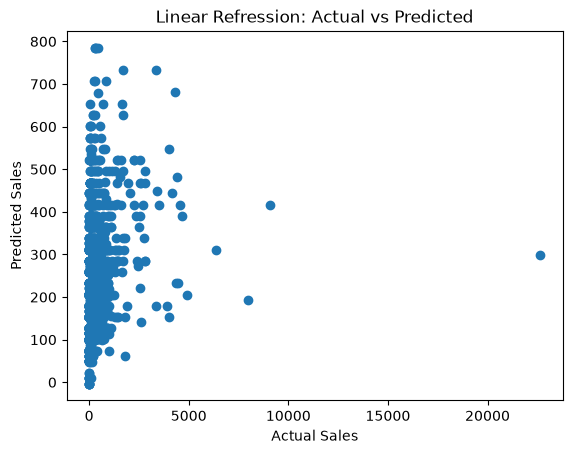

In [16]:
# Choose target: Predicting sales using quantity and discount
X = df[["quantity", "discount"]]
y = df["sales"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Prediction
y_pred = lr.predict(X_test)
print("Sample Linear Regression Predictions:", y_pred[:10])

# Plot Actual vs Predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Linear Refression: Actual vs Predicted")
plt.show()

### Part 2 - Regression Metrics

#### Task 2: Regression Metrics

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
print("MAE:", mae)

mse=mean_squared_error(y_test, y_pred)
print("MSE:", mse)

rmse = np.sqrt(mse)
print("RSME:", rmse)

r2 = r2_score(y_test, y_pred)
print("R2 Score:", r2)

MAE: 230.1645893341486
MSE: 67469.51871535163
RSME: 259.74895325169575
R2 Score: -440899.9152274001


### Part 3 - Classification Algorithms

#### Task 3: Logistic Regression

In [29]:
from sklearn.linear_model import LogisticRegression

df["profitable"] = (df['profit'] > 0).astype(int)

X = df[['quantity', 'discount', 'sales']]
y = df['profitable']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

log_reg = LogisticRegression(max_iter=200)
log_reg.fit(X_train, y_train)
y_pred_log = log_reg.predict(X_test)

print("Logistic Regression Predictions:", y_pred_log[:10])

Logistic Regression Predictions: [1 1 1 0 1 1 0 1 0 1]


#### Task 4: Naive Bayes

In [32]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

print("Naive Bayes Predictions:", y_pred_nb[:10])

Naive Bayes Predictions: [1 1 1 0 1 1 0 1 0 1]


#### Task 5: K-Nearest Neighbors (KNN)

In [39]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

for k in [3, 5, 7]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred_knn = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred_knn)
    print(f"K={k}, Predictions: {y_pred_knn[:10]}, Accuracy={acc:.3f}")

K=3, Predictions: [1 1 1 1 1 1 1 1 1 1], Accuracy=0.853
K=5, Predictions: [1 1 1 1 1 1 1 1 1 1], Accuracy=0.846
K=7, Predictions: [1 1 1 1 0 1 1 1 1 1], Accuracy=0.842


### Part 4 - CLassification Metrics

#### Task 6: Classification Metrics

In [43]:
from sklearn.metrics import classification_report, confusion_matrix

print("Logistic Regression Report:\n", classification_report(y_test, y_pred_log))

print("Naive Bayes Report:\n", classification_report(y_test, y_pred_nb))

print("KNN Report:\n", classification_report(y_test, y_pred_knn))

print("Confusion Matrics (Logistic Regression):\n", confusion_matrix(y_test, y_pred_log))

Logistic Regression Report:
               precision    recall  f1-score   support

           0       0.98      0.67      0.80       377
           1       0.93      1.00      0.96      1622

    accuracy                           0.94      1999
   macro avg       0.96      0.84      0.88      1999
weighted avg       0.94      0.94      0.93      1999

Naive Bayes Report:
               precision    recall  f1-score   support

           0       0.98      0.65      0.78       377
           1       0.93      1.00      0.96      1622

    accuracy                           0.93      1999
   macro avg       0.95      0.83      0.87      1999
weighted avg       0.94      0.93      0.93      1999

KNN Report:
               precision    recall  f1-score   support

           0       0.68      0.31      0.42       377
           1       0.86      0.97      0.91      1622

    accuracy                           0.84      1999
   macro avg       0.77      0.64      0.67      1999
weighted av

### Part 5 - Model Behavior & Learning Concepts

#### Task 7: Overfitting & Underfitting

In [48]:
# Overfitting
# Create KNN model with k = 1
knn = KNeighborsClassifier(n_neighbors=1)

knn.fit(X_train, y_train)

train_acc = knn.score(X_train, y_train)

test_acc = knn.score(X_test, y_test)

print("\nOverfitting Model Result")
print("Training Accuracy :", train_acc)
print("Testing Accuracy :", test_acc)


Overfitting Model Result
Training Accuracy : 0.9883677298311445
Testing Accuracy : 0.870935467733867


In [50]:
# Underfitting
# Create simple Logistic Regression model
log_reg = LogisticRegression(max_iter=200)

log_reg.fit(X_train[["quantity"]], y_train)

train_acc = log_reg.score(X_train[["quantity"]], y_train)

test_acc = log_reg.score(X_test[["quantity"]], y_test)

print("Underfitting Model Results")
print("Training Accuracy :", train_acc)
print("Testing Accuracy :", test_acc)

Underfitting Model Results
Training Accuracy : 0.8050031269543465
Testing Accuracy : 0.8114057028514257


#### Task 8: Bias & Variance

1. What is Bias in Machine Learning Models?

Answer:

Bias is the error caused when a machine learning model makes overly simple assumptions about the data. A model with high bias cannot capture the underlying patterns properly and therefore performs poorly on both training and testing data.

Example:
Suppose we want to predict house prices using many factors such as area, location, number of rooms, and age of the house. If we use only one factor (area), the model may miss important information and make inaccurate predictions.

High Bias leads to: Underfitting

2. What is Variance?

Answer:

Variance is the error caused when a model becomes too sensitive to the training data. A high variance model learns not only the patterns but also the noise and small fluctuations present in the training dataset.

As a result, it performs very well on training data but poorly on unseen test data.

Example:
A Decision Tree with very large depth may memorize the training data instead of learning general patterns.

High Variance leads to: Overfitting

3. How do Bias and Variance relate to Underfitting and Overfitting?

Answer:

Bias and variance are closely related to model performance.

Condition	   Bias	        Variance	       Result
Underfitting   High	        Low	               Model is too simple
Overfitting	   Low	        High	           Model is too complex
Good Fit	   Moderate	    Moderate	       Balanced performance


Underfitting:

Model is too simple.
Cannot learn important patterns.
Training accuracy is low.
Testing accuracy is low.
High Bias, Low Variance.

Overfitting:

Model is too complex.
Memorizes training data.
Training accuracy is very high.
Testing accuracy is low.
Low Bias, High Variance.

4. How can we Reduce Overfitting?

Answer:

Overfitting can be reduced using the following techniques:

Increase Training Data
More data helps the model learn general patterns instead of memorizing data.
Reduce Model Complexity
Use simpler models or limit model parameters.
Cross Validation
Helps evaluate model performance on different subsets of data.
Feature Selection
Remove unnecessary or irrelevant features.
Regularization
Techniques such as L1 (Lasso) and L2 (Ridge) prevent the model from becoming overly complex.
Pruning (Decision Trees)
Limit tree depth to avoid memorizing training data.
Use Appropriate K Value in KNN
Avoid very small values such as k=1.